# 1. Me importo todas las librerías que voy a necesitar

In [1]:
import pandas as pd
import seaborn as sns
import json
import numpy as np
import requests
import os
import matplotlib.pyplot as plt

# 2 Hago merge de todos los dataset limpios

In [2]:
vivienda = pd.read_csv("../data/Depurados/limpio_vivienda.csv")
turismo = pd.read_csv("../data/Depurados/limpio_turistas_pernoctan.csv")
inflacion = pd.read_csv("../data/Depurados/limpio_inflacion.csv")
pib = pd.read_csv("../data/Depurados/limpio_pib.csv")

In [3]:
print(vivienda)
print(turismo)
print(inflacion)
print(pib)

              pais iso3  anio  crec._precio_(%)
0        Australia  AUS  2015               9.0
1        Australia  AUS  2016               5.5
2        Australia  AUS  2017               8.4
3        Australia  AUS  2018              -1.4
4        Australia  AUS  2019              -4.0
..             ...  ...   ...               ...
565  United States  USA  2020               6.7
566  United States  USA  2021              15.1
567  United States  USA  2022              12.8
568  United States  USA  2023               4.0
569  United States  USA  2024               4.3

[570 rows x 4 columns]
        pais iso3  anio  numero_turistas  crec._turistas_(%)
0      Aruba  ABW  2015          1225000                 NaN
1      Aruba  ABW  2016          1102000               -10.0
2      Aruba  ABW  2017          1070500                -2.9
3      Aruba  ABW  2018          1082000                 1.1
4      Aruba  ABW  2019          1119000                 3.4
...      ...  ...   ...           

# 3 Quitamos columnas con números absolutos de turismo, pib e inflación para dejar solo tasa de crecimiento

In [4]:
turismo = turismo[["pais", "iso3", "anio", "crec._turistas_(%)"]]
inflacion = inflacion[["pais", "iso3", "anio", "inflacion_(%)"]]
pib = pib[["pais", "iso3", "anio", "crecim_pib_(%)"]]
print(turismo.shape, inflacion.shape, pib.shape)

(1518, 4) (1811, 4) (1858, 4)


In [5]:
print(vivienda)
print(turismo)
print(inflacion)
print(pib)

              pais iso3  anio  crec._precio_(%)
0        Australia  AUS  2015               9.0
1        Australia  AUS  2016               5.5
2        Australia  AUS  2017               8.4
3        Australia  AUS  2018              -1.4
4        Australia  AUS  2019              -4.0
..             ...  ...   ...               ...
565  United States  USA  2020               6.7
566  United States  USA  2021              15.1
567  United States  USA  2022              12.8
568  United States  USA  2023               4.0
569  United States  USA  2024               4.3

[570 rows x 4 columns]
        pais iso3  anio  crec._turistas_(%)
0      Aruba  ABW  2015                 NaN
1      Aruba  ABW  2016               -10.0
2      Aruba  ABW  2017                -2.9
3      Aruba  ABW  2018                 1.1
4      Aruba  ABW  2019                 3.4
...      ...  ...   ...                 ...
1513  Zambia  ZMB  2017                 5.5
1514  Zambia  ZMB  2018                 6.2
1515

# 4 Hago el merge entre todos los dataset usando el código iso3

In [6]:
datos_mergeados = vivienda.merge( turismo[["iso3", "anio", "crec._turistas_(%)"]], on=["iso3", "anio"], how="left")
print(datos_mergeados.shape)

(570, 5)


In [7]:
datos_mergeados = datos_mergeados.merge(inflacion[["iso3", "anio", "inflacion_(%)"]],on=["iso3", "anio"], how="left")
print(datos_mergeados.shape)


(570, 6)


In [8]:
datos_mergeados = datos_mergeados.merge(pib[["iso3", "anio", "crecim_pib_(%)"]],on=["iso3", "anio"], how="left")
print(datos_mergeados.shape)

(570, 7)


In [9]:
print(datos_mergeados)

              pais iso3  anio  crec._precio_(%)  crec._turistas_(%)  \
0        Australia  AUS  2015               9.0                 NaN   
1        Australia  AUS  2016               5.5                 NaN   
2        Australia  AUS  2017               8.4                 NaN   
3        Australia  AUS  2018              -1.4                 NaN   
4        Australia  AUS  2019              -4.0                 NaN   
..             ...  ...   ...               ...                 ...   
565  United States  USA  2020               6.7               -75.8   
566  United States  USA  2021              15.1                16.0   
567  United States  USA  2022              12.8               127.9   
568  United States  USA  2023               4.0                30.7   
569  United States  USA  2024               4.3                 9.1   

     inflacion_(%)  crecim_pib_(%)  
0              1.5             NaN  
1              1.3           -12.1  
2              1.9             8.1  

# 5 Compruebo los NaN que hay por columnas

In [10]:
datos_mergeados.isnull().sum()

pais                    0
iso3                    0
anio                    0
crec._precio_(%)        0
crec._turistas_(%)    162
inflacion_(%)           0
crecim_pib_(%)         57
dtype: int64

In [11]:
datos_mergeados.notnull().sum()

pais                  570
iso3                  570
anio                  570
crec._precio_(%)      570
crec._turistas_(%)    408
inflacion_(%)         570
crecim_pib_(%)        513
dtype: int64

In [12]:
datos_mergeados["iso3"].nunique()

57

# 6 Elimino los NaN

In [13]:
datos_mergeados = datos_mergeados.dropna()
datos_mergeados.shape

(408, 7)

In [14]:
datos_mergeados = datos_mergeados.reset_index(drop=True)
print(datos_mergeados)

              pais iso3  anio  crec._precio_(%)  crec._turistas_(%)  \
0          Austria  AUT  2016               7.4                 5.2   
1          Austria  AUT  2017               3.8                 4.8   
2          Austria  AUT  2018               6.9                 4.6   
3          Austria  AUT  2019               4.0                 3.5   
4          Austria  AUT  2020               7.0               -52.7   
..             ...  ...   ...               ...                 ...   
403  United States  USA  2020               6.7               -75.8   
404  United States  USA  2021              15.1                16.0   
405  United States  USA  2022              12.8               127.9   
406  United States  USA  2023               4.0                30.7   
407  United States  USA  2024               4.3                 9.1   

     inflacion_(%)  crecim_pib_(%)  
0              0.9             2.6  
1              2.1             4.7  
2              2.0             8.5  

In [15]:
datos_mergeados["iso3"].nunique()

54

# 7 verifico cuantos países tienen toda la serie histórica completa: hay 25 países con datos completos (sin NaN). Se trabaja con los 25 países que tienen datos completos de 2016 a 2024. Se prioriza una serie completa y comparable (los mismos países todos los años, incluidos los posteriores a la pandemia) frente a una muestra mayor pero con años distintos por país.

In [16]:
datos_mergeados.groupby("iso3").size().value_counts()

9    25
7    18
6     6
4     4
5     1
Name: count, dtype: int64

In [31]:
datos_mergeados.head(20)

,pais,iso3,anio,crec._precio_(%),crec._turistas_(%),inflacion_(%),crecim_pib_(%)
0,Austria,AUT,2016,7.4,5.2,0.9,2.6
1,Austria,AUT,2017,3.8,4.8,2.1,4.7
2,Austria,AUT,2018,6.9,4.6,2.0,8.5
3,Austria,AUT,2019,4.0,3.5,1.5,-2.6
4,Austria,AUT,2020,7.0,-52.7,1.4,-2.3
5,Austria,AUT,2021,11.8,-15.7,2.8,10.1
6,Austria,AUT,2022,10.4,106.0,8.5,-2.4
7,Belgium,BEL,2016,2.3,-10.5,2.0,2.3
8,Belgium,BEL,2017,3.5,12.1,2.1,5.2
9,Belgium,BEL,2018,3.0,8.8,2.1,7.8


In [37]:
conteo = datos_mergeados.groupby("iso3").size()
datos_mergeados_2 = datos_mergeados[datos_mergeados["iso3"].isin(conteo[conteo == 9].index)]
datos_mergeados_2 = datos_mergeados_2.reset_index(drop=True)
print(datos_mergeados_2["iso3"].nunique(), datos_mergeados_2.shape)

25 (225, 7)


# 9 Calculo las medianas agregadas de todos los países. Se usa la mediana y no la media porque la pandemia de COVID-19 genera valores atípicos (outliers), sobre todo en el crecimiento del turismo, y la mediana es más robusta a ellos

In [38]:
mediana_mundial = datos_mergeados_2.groupby("anio").median(numeric_only=True).round(1)
print(mediana_mundial)

      crec._precio_(%)  crec._turistas_(%)  inflacion_(%)  crecim_pib_(%)
anio                                                                     
2016               5.4                 9.3            0.6             2.8
2017               5.3                 9.9            2.0             7.4
2018               5.8                 5.1            2.0             7.4
2019               3.7                 2.5            1.7            -0.4
2020               4.6               -74.4            1.0            -3.8
2021               8.2                 6.7            3.1            16.1
2022               8.9               136.2            8.0            -0.4
2023               4.0                21.1            5.5            10.2
2024               6.0                 8.6            2.9             4.9


# 11 Calculo la mediana agregada de todos los años de cada variable

In [40]:
mediana_total = datos_mergeados_2[["crec._precio_(%)", "crec._turistas_(%)", "inflacion_(%)", "crecim_pib_(%)"]].median().round(1)
print(mediana_total)

crec._precio_(%)      6.0
crec._turistas_(%)    7.9
inflacion_(%)         2.4
crecim_pib_(%)        4.4
dtype: float64


# 12 Hago tabla del Top 15 más España

In [65]:
tabla = vivienda_real.groupby("pais")[["crec._precio_(%)", "crec_real_(%)"]].mean().round(1)
tabla = tabla.sort_values("crec_real_(%)", ascending=False).reset_index()
tabla["puesto"] = tabla.index + 1

top15_espana = pd.concat([tabla.head(15), tabla[tabla["pais"] == "Spain"]])
top15_espana = top15_espana[["puesto", "pais", "crec._precio_(%)", "crec_real_(%)"]]
top15_espana

,puesto,pais,crec._precio_(%),crec_real_(%)
0,1,Türkiye,41.0,13.6
1,2,Hungary,13.5,8.2
2,3,Portugal,8.8,6.8
3,4,Iceland,10.6,6.6
4,5,Ireland,7.5,5.6
5,6,Serbia,9.9,5.5
6,7,Lithuania,9.4,5.0
7,8,Slovenia,7.4,4.9
8,9,Netherlands,7.6,4.8
9,10,Czechia,8.9,4.6


# 10 Procedemos con las visualizaciones 

## 10.1 Mostramos la gráfica comparada en serie histórica con variables agregadas por año

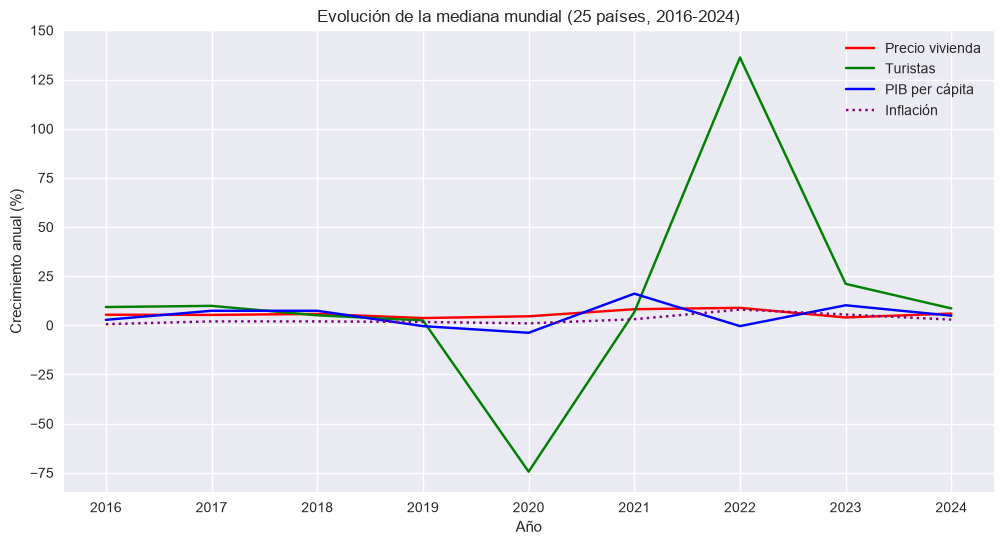

In [56]:
datos_graf = mediana_mundial.reset_index()

plt.style.use("seaborn-v0_8")
plt.figure(figsize=(12, 6))

sns.lineplot(data=datos_graf, x="anio", y="crec._precio_(%)", label="Precio vivienda", color="red")
sns.lineplot(data=datos_graf, x="anio", y="crec._turistas_(%)", label="Turistas", color="green")
sns.lineplot(data=datos_graf, x="anio", y="crecim_pib_(%)", label="PIB per cápita", color="blue")
sns.lineplot(data=datos_graf, x="anio", y="inflacion_(%)", label="Inflación", color="purple", linestyle=":")

plt.yticks(np.arange(-75, 151, 25))
plt.title("Evolución de la mediana mundial (25 países, 2016-2024)")
plt.xlabel("Año")
plt.ylabel("Crecimiento anual (%)")
plt.legend()





### 10.1.1 Metermos zoon para visualizar mejor la gráfica. 

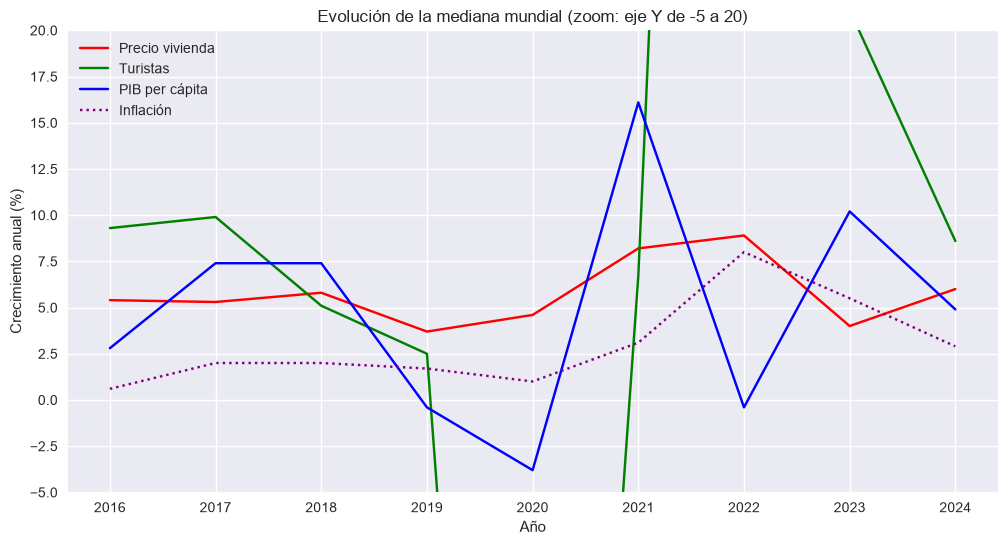

In [58]:
plt.style.use("seaborn-v0_8")
plt.figure(figsize=(12, 6))

sns.lineplot(data=datos_graf, x="anio", y="crec._precio_(%)", label="Precio vivienda", color="red")
sns.lineplot(data=datos_graf, x="anio", y="crec._turistas_(%)", label="Turistas", color="green")
sns.lineplot(data=datos_graf, x="anio", y="crecim_pib_(%)", label="PIB per cápita", color="blue")
sns.lineplot(data=datos_graf, x="anio", y="inflacion_(%)", label="Inflación", color="purple", linestyle=":")

plt.ylim(-5, 20)
plt.yticks(np.arange(-5, 21, 2.5))
plt.title("Evolución de la mediana mundial (zoom: eje Y de -5 a 20)")
plt.xlabel("Año")
plt.ylabel("Crecimiento anual (%)")
plt.legend()
plt.show()

# 10. 2 Top 15 sin merge de inflacion

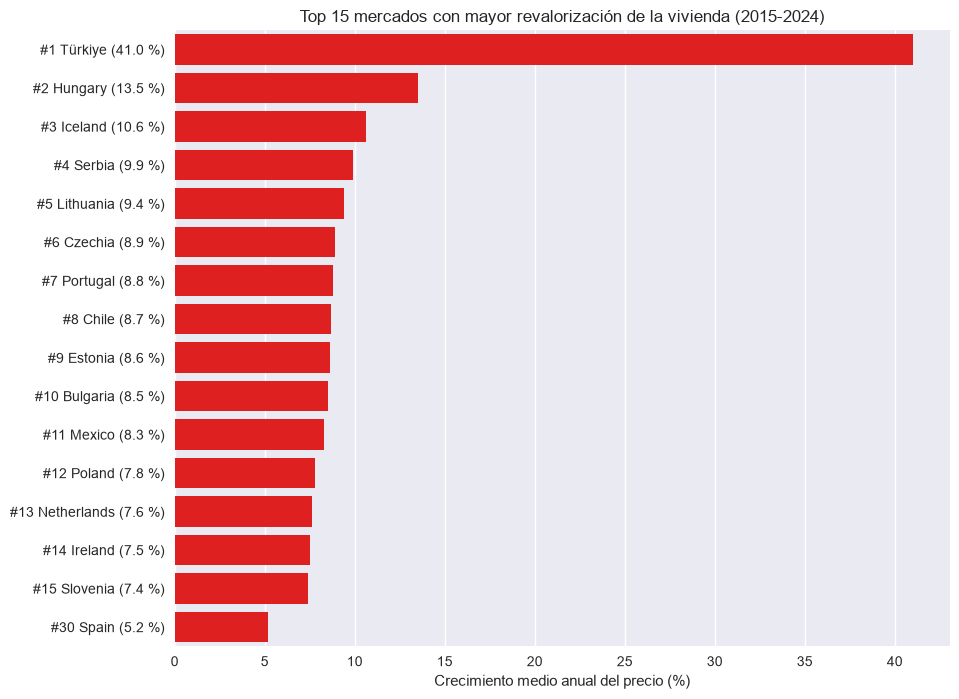

In [67]:
ranking = vivienda.groupby("pais")["crec._precio_(%)"].mean().round(1)
ranking = ranking.sort_values(ascending=False).reset_index()
ranking["puesto"] = ranking.index + 1
ranking["etiqueta"] = "#" + ranking["puesto"].astype(str) + " " + ranking["pais"] + " (" + ranking["crec._precio_(%)"].astype(str) + " %)"
top15 = pd.concat([ranking.head(15), ranking[ranking["pais"] == "Spain"]])

plt.style.use("seaborn-v0_8")
plt.figure(figsize=(10, 8))

sns.barplot(data=top15, x="crec._precio_(%)", y="etiqueta", color="red")

plt.title("Top 15 mercados con mayor revalorización de la vivienda (2015-2024)")
plt.xlabel("Crecimiento medio anual del precio (%)")
plt.ylabel("")
plt.show()

# 10.3  Top 15 países donde más ha subido el precio de la vivienda teniendo en cuenta la inflación (creciemito real = crecimiento precio vivienda - crecimiento infalación)

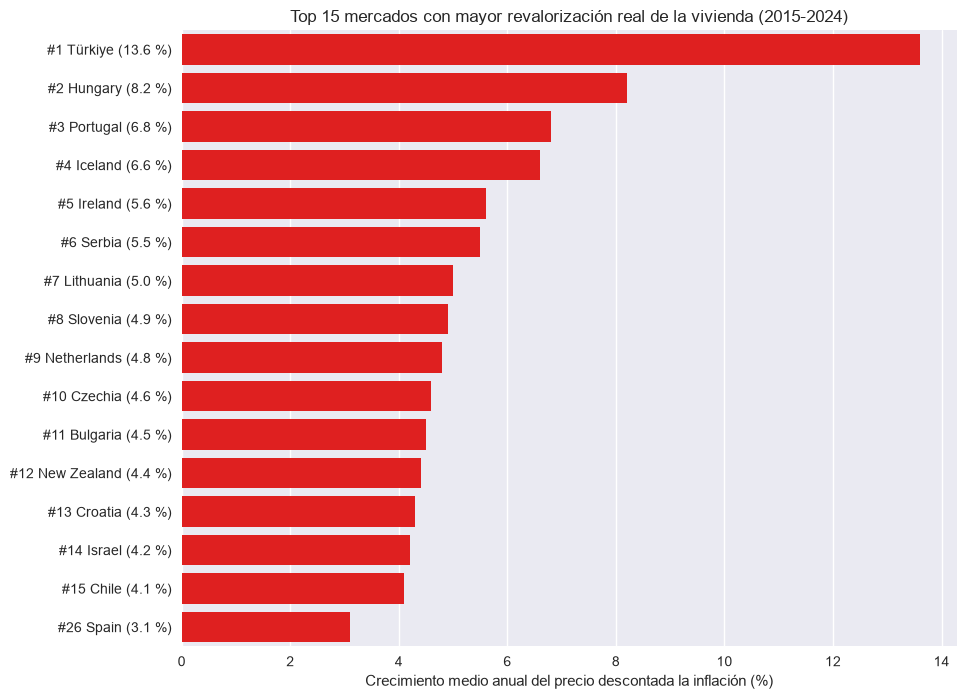

In [68]:
ranking = vivienda_real.groupby("pais")["crec_real_(%)"].mean().round(1)
ranking = ranking.sort_values(ascending=False).reset_index()
ranking["puesto"] = ranking.index + 1
ranking["etiqueta"] = "#" + ranking["puesto"].astype(str) + " " + ranking["pais"] + " (" + ranking["crec_real_(%)"].astype(str) + " %)"
top15_real = pd.concat([ranking.head(15), ranking[ranking["pais"] == "Spain"]])

plt.style.use("seaborn-v0_8")
plt.figure(figsize=(10, 8))

sns.barplot(data=top15_real, x="crec_real_(%)", y="etiqueta", color="red")

plt.title("Top 15 mercados con mayor revalorización real de la vivienda (2015-2024)")
plt.xlabel("Crecimiento medio anual del precio descontada la inflación (%)")
plt.ylabel("")
plt.show()

# 11. Respuesta a la 1º HIPÓTESIS: ¿Tiene alguna correlación el aumento del turismo con el incremento del precio de la vivienda a nivel mundial?

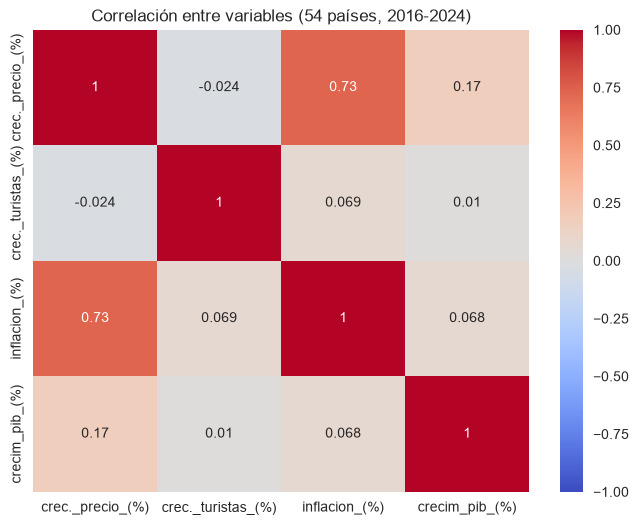

In [62]:
columnas = ["crec._precio_(%)", "crec._turistas_(%)", "inflacion_(%)", "crecim_pib_(%)"]
corr = datos_mergeados[columnas].corr()

plt.style.use("seaborn-v0_8")
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlación entre variables (54 países, 2016-2024)")
plt.show()

In [71]:
sin_pandemia = datos_mergeados[datos_mergeados["anio"].between(2020, 2022)]
print(sin_pandemia[columnas].corr().round(2)["crec._precio_(%)"])
print(datos_mergeados_2[columnas].corr().round(2)["crec._precio_(%)"])

crec._precio_(%)      1.00
crec._turistas_(%)   -0.02
inflacion_(%)         0.86
crecim_pib_(%)        0.16
Name: crec._precio_(%), dtype: float64
crec._precio_(%)      1.00
crec._turistas_(%)   -0.11
inflacion_(%)         0.32
crecim_pib_(%)        0.23
Name: crec._precio_(%), dtype: float64


# 12 Respuesta a la  2º HIPÓTESIS

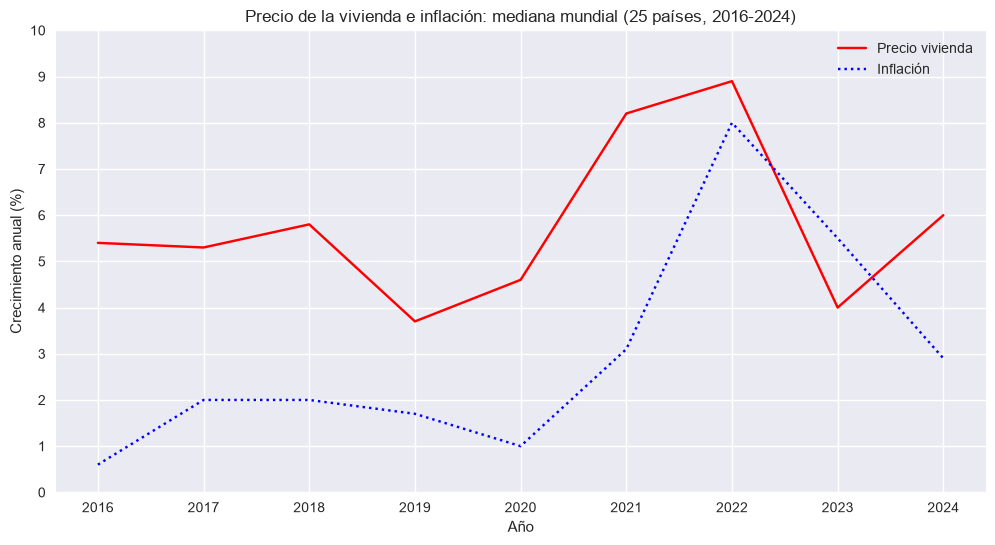

In [70]:
datos_graf = mediana_mundial.reset_index()

plt.style.use("seaborn-v0_8")
plt.figure(figsize=(12, 6))

sns.lineplot(data=datos_graf, x="anio", y="crec._precio_(%)", label="Precio vivienda", color="red")
sns.lineplot(data=datos_graf, x="anio", y="inflacion_(%)", label="Inflación", color="blue", linestyle=":")

plt.yticks(np.arange(0, 11, 1))
plt.title("Precio de la vivienda e inflación: mediana mundial (25 países, 2016-2024)")
plt.xlabel("Año")
plt.ylabel("Crecimiento anual (%)")
plt.legend()
plt.show()

# 13 

In [74]:
import sys
sys.path.append("..")
from utils.archivos import guardar_dataset

guardar_dataset(datos_mergeados, "merge_todos_paises.csv")
guardar_dataset(datos_mergeados_2, "merge_panel_25_paises_16-24.csv")
guardar_dataset(mediana_mundial, "merge_mediana_mundial.csv", index=True)
guardar_dataset(vivienda_real, "merge_vivienda_inflacion.csv")

Guardado: c:\Users\Agus\Bootcamp\proyectos\4_PROYECTO_2 EDA\src\data\Mergeados\merge_todos_paises.csv
Guardado: c:\Users\Agus\Bootcamp\proyectos\4_PROYECTO_2 EDA\src\data\Mergeados\merge_panel_25_paises_16-24.csv
Guardado: c:\Users\Agus\Bootcamp\proyectos\4_PROYECTO_2 EDA\src\data\Mergeados\merge_mediana_mundial.csv
Guardado: c:\Users\Agus\Bootcamp\proyectos\4_PROYECTO_2 EDA\src\data\Mergeados\merge_vivienda_inflacion.csv
